<a href="https://colab.research.google.com/github/peteraggi/ColabFavourites/blob/main/CoffeeCare_Model_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CoffeeCare Model Training
Trains a MobileNetV3-Large classifier (transfer learning from ImageNet) on `coffeecare_dataset_v1.zip`.

- **Classes (7):** brown_eye_spot, coffee_leaf_rust, healthy, leaf_miner, phoma_leaf_blight, red_spider_mite, unknown
- **Splits:** train / val / test_public (same sources as training) / **test_uganda** (Soroti, never trained on)
- **Output:** `coffee_model.tflite` + `labels.txt` for the CoffeeCare backend and mobile app

In [2]:
import os
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

# print('TensorFlow:', tf.__version__)
# print('Keras:', keras.__version__)
# print('GPU:', tf.config.list_physical_devices('GPU'))

from google.colab import drive
drive.mount('/content/drive')

# Permanent storage on Google Drive
BASE_DIR = '/content/drive/MyDrive/ColabFavourites/CoffeeCare'
DATASET_DIR = os.path.join(BASE_DIR, 'dataset')
MODELS_DIR = os.path.join(BASE_DIR, 'models')

DATASET_VERSION = 'v1'
DATASET_ZIP = os.path.join(DATASET_DIR, f'coffeecare_dataset_{DATASET_VERSION}.zip')
SPLITS_CSV = os.path.join(BASE_DIR, f'splits_{DATASET_VERSION}.csv')

# Fast local copy of the dataset (wiped when the session ends)
LOCAL_DATASET = '/content/coffeecare_dataset'

print('Dataset zip found:', os.path.exists(DATASET_ZIP))
print('Split record found:', os.path.exists(SPLITS_CSV))

Mounted at /content/drive
Dataset zip found: True
Split record found: True


In [3]:
CLASS_NAMES = [
    'brown_eye_spot',
    'coffee_leaf_rust',
    'healthy',
    'leaf_miner',
    'phoma_leaf_blight',
    'red_spider_mite',
    'unknown'
]
SPLITS = ['train', 'val', 'test_public', 'test_uganda']

if not os.path.exists(LOCAL_DATASET):
    local_zip = '/content/coffeecare_dataset.zip'
    print('Copying zip from Drive...')
    shutil.copy(DATASET_ZIP, local_zip)
    print('Unzipping...')
    shutil.unpack_archive(local_zip, LOCAL_DATASET)
    os.remove(local_zip)
else:
    print('Already unzipped:', LOCAL_DATASET)

counts = {}
for split in SPLITS:
    counts[split] = {}
    for class_name in CLASS_NAMES:
        folder = os.path.join(LOCAL_DATASET, split, class_name)
        counts[split][class_name] = len(os.listdir(folder)) if os.path.exists(folder) else 0

print()
print(pd.DataFrame(counts))

Copying zip from Drive...
Unzipping...

                   train   val  test_public  test_uganda
brown_eye_spot      6252   783          782            0
coffee_leaf_rust    7767   874          762         1031
healthy            16969  1453         1494         1079
leaf_miner         13901  1705         1625            0
phoma_leaf_blight   5624   668          625         1110
red_spider_mite      133    17           17            0
unknown             2800   350          350            0


In [4]:
IMAGE_SIZE = 224      # what the model looks at (MobileNetV3's standard input)
LOADED_SIZE = 256     # the size the images were saved at in the dataset notebook
BATCH_SIZE = 64       # images processed together in one step
SEED = 42

for split in SPLITS:
    for class_name in CLASS_NAMES:
        os.makedirs(os.path.join(LOCAL_DATASET, split, class_name), exist_ok=True)

def load_split(split, shuffle):
    """Read one split's images from its class folders, in batches"""
    return keras.utils.image_dataset_from_directory(
        os.path.join(LOCAL_DATASET, split),
        labels='inferred',
        label_mode='int',
        class_names=CLASS_NAMES,
        image_size=(LOADED_SIZE, LOADED_SIZE),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED
    )

train_raw = load_split('train', shuffle=True)
val_raw = load_split('val', shuffle=False)
test_public_raw = load_split('test_public', shuffle=False)
test_uganda_raw = load_split('test_uganda', shuffle=False)

print()
print('Class order matches CLASS_NAMES:', train_raw.class_names == CLASS_NAMES)

Found 53446 files belonging to 7 classes.
Found 5850 files belonging to 7 classes.
Found 5655 files belonging to 7 classes.
Found 3220 files belonging to 7 classes.

Class order matches CLASS_NAMES: True


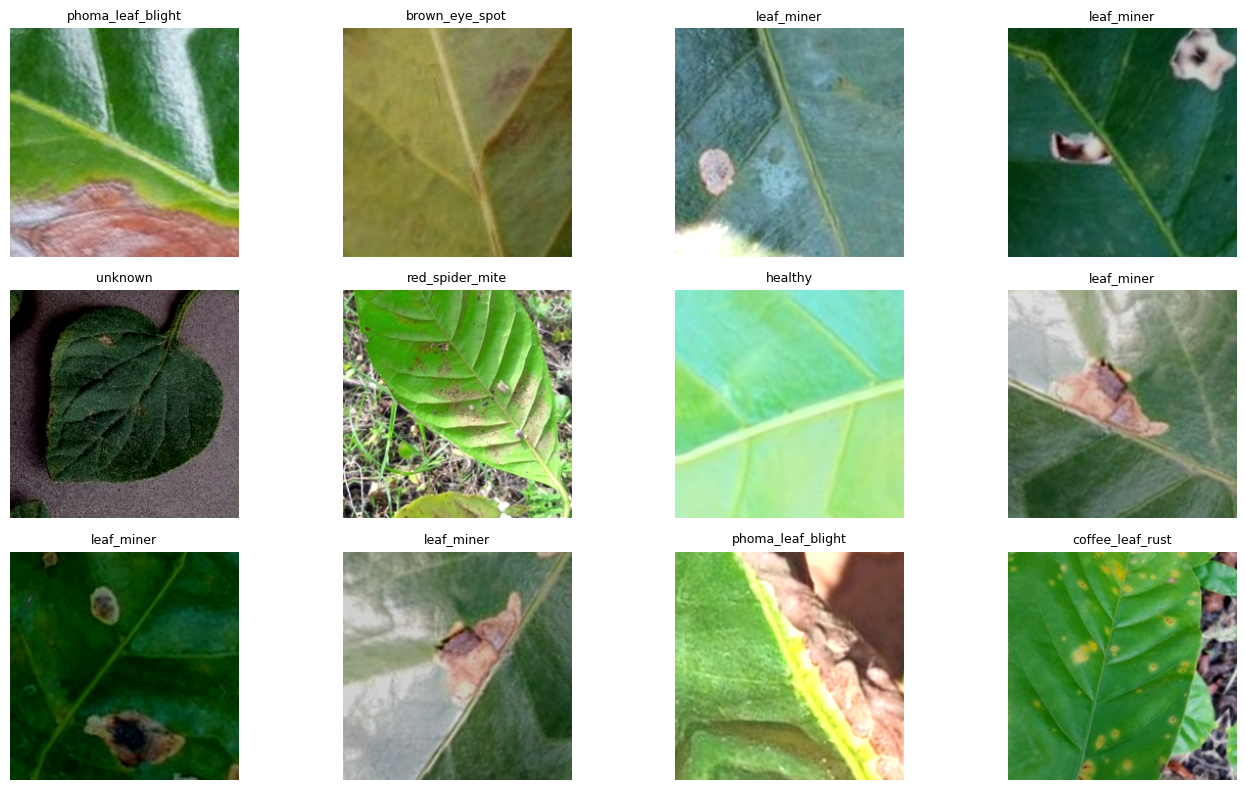

In [5]:
augment = keras.Sequential([
    keras.layers.RandomCrop(IMAGE_SIZE, IMAGE_SIZE, seed=SEED),
    keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED),
    keras.layers.RandomRotation(0.1, fill_mode='reflect', seed=SEED),
    keras.layers.RandomBrightness(0.2, value_range=(0, 255), seed=SEED),
    keras.layers.RandomContrast(0.2, seed=SEED),
], name='augmentation')

resize_only = keras.layers.Resizing(IMAGE_SIZE, IMAGE_SIZE)

def prepare_train(images, labels):
    """Training: a different random variation of every image, every time"""
    return augment(images, training=True), labels

def prepare_eval(images, labels):
    """Validation and testing: the whole image, just resized (no randomness)"""
    return resize_only(images), labels

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.map(prepare_train, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_raw.map(prepare_eval, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_public_ds = test_public_raw.map(prepare_eval, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_uganda_ds = test_uganda_raw.map(prepare_eval, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Preview: what the model will see during training
images, labels = next(iter(train_ds))
plt.figure(figsize=(14, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(np.clip(images[i].numpy() / 255.0, 0, 1))
    plt.title(CLASS_NAMES[int(labels[i])], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

In [6]:
# How strongly to correct the imbalance:
#   1.0 = fully balanced (every class counts equally in total)
#   0.5 = softened (square root): rare classes count more, but not extremely
#   0.0 = no weighting
CLASS_WEIGHT_POWER = 0.5

train_counts = np.array([counts['train'][c] for c in CLASS_NAMES])
total = train_counts.sum()

weights = (total / (len(CLASS_NAMES) * train_counts)) ** CLASS_WEIGHT_POWER
weights = weights * total / (train_counts * weights).sum()    # keep the average weight per image at 1

class_weight = {i: float(w) for i, w in enumerate(weights)}

print(pd.DataFrame({
    'train_images': train_counts,
    'weight': np.round(weights, 2)
}, index=CLASS_NAMES))

                   train_images  weight
brown_eye_spot             6252    1.22
coffee_leaf_rust           7767    1.09
healthy                   16969    0.74
leaf_miner                13901    0.82
phoma_leaf_blight          5624    1.28
red_spider_mite             133    8.35
unknown                    2800    1.82


In [7]:
base_model = keras.applications.MobileNetV3Large(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights='imagenet',
    pooling='avg',
    include_preprocessing=True
)
base_model.trainable = False      # phase 1: keep ImageNet knowledge frozen

inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name='image')
x = base_model(inputs, training=False)
x = keras.layers.Dropout(0.3, name='dropout')(x)
outputs = keras.layers.Dense(len(CLASS_NAMES), activation='softmax', name='predictions')(x)

model = keras.Model(inputs, outputs, name='coffeecare_mobilenetv3')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print('Total parameters    :', f'{model.count_params():,}')
print('Trainable parameters:', f'{trainable:,}')

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Total parameters    : 3,003,079
Trainable parameters: 6,727


In [8]:
RUN_NAME = f'mobilenetv3_{DATASET_VERSION}'
RUN_DIR = os.path.join(MODELS_DIR, RUN_NAME)
os.makedirs(RUN_DIR, exist_ok=True)

PHASE1_EPOCHS = 10

phase1_callbacks = [
    keras.callbacks.ModelCheckpoint(
        os.path.join(RUN_DIR, 'phase1_best.keras'),
        monitor='val_loss', save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    keras.callbacks.CSVLogger(os.path.join(RUN_DIR, 'phase1_log.csv'))
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=PHASE1_EPOCHS,
    class_weight=class_weight,
    callbacks=phase1_callbacks
)

Epoch 1/10
836/836 ━━━━━━━━━━━━━━━━━━━━ 0s 643ms/step - accuracy: 0.8472 - loss: 0.5312
Epoch 1: val_loss improved from None to 0.10356, saving model to /content/drive/MyDrive/ColabFavourites/CoffeeCare/models/mobilenetv3_v1/phase1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ColabFavourites/CoffeeCare/models/mobilenetv3_v1/phase1_best.keras
836/836 ━━━━━━━━━━━━━━━━━━━━ 627s 690ms/step - accuracy: 0.9266 - loss: 0.2725 - val_accuracy: 0.9718 - val_loss: 0.1036
Epoch 2/10
835/836 ━━━━━━━━━━━━━━━━━━━━ 0s 612ms/step - accuracy: 0.9672 - loss: 0.1221
Epoch 2: val_loss improved from 0.10356 to 0.07943, saving model to /content/drive/MyDrive/ColabFavourites/CoffeeCare/models/mobilenetv3_v1/phase1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ColabFavourites/CoffeeCare/models/mobilenetv3_v1/phase1_best.keras
836/836 ━━━━━━━━━━━━━━━━━━━━ 519s 620ms/step - accuracy: 0.9696 - loss: 0.1128 - val_accuracy: 0.9738 - val_loss: 0.0794
Epoch 3/10
835/836 

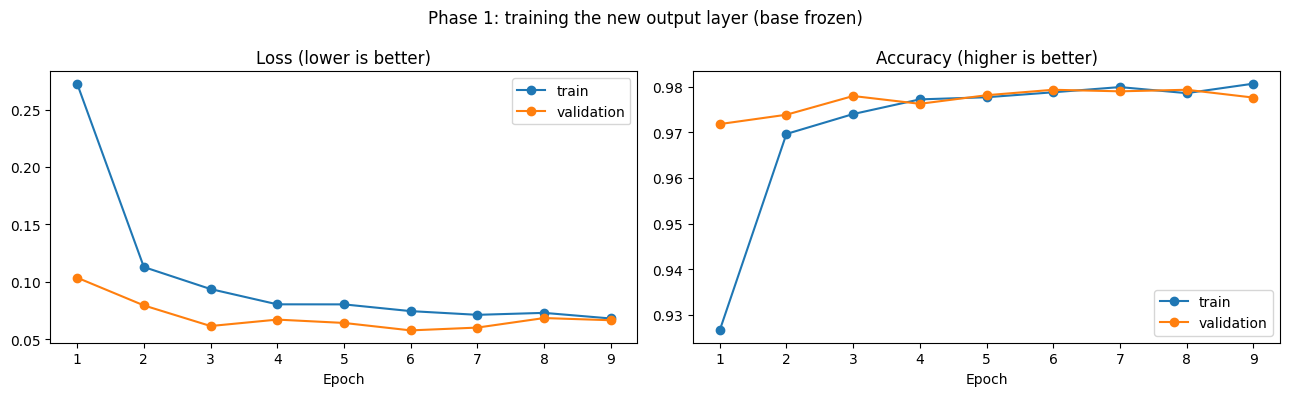

   epoch  accuracy    loss  val_accuracy  val_loss
0      0    0.9266  0.2725        0.9718    0.1036
1      1    0.9696  0.1128        0.9738    0.0794
2      2    0.9740  0.0937        0.9779    0.0615
3      3    0.9772  0.0804        0.9762    0.0671
4      4    0.9777  0.0803        0.9781    0.0642
5      5    0.9788  0.0745        0.9793    0.0577
6      6    0.9799  0.0712        0.9790    0.0601
7      7    0.9786  0.0729        0.9793    0.0684
8      8    0.9807  0.0680        0.9776    0.0665


In [9]:
log1 = pd.read_csv(os.path.join(RUN_DIR, 'phase1_log.csv'))

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4))

ax_loss.plot(log1['epoch'] + 1, log1['loss'], marker='o', label='train')
ax_loss.plot(log1['epoch'] + 1, log1['val_loss'], marker='o', label='validation')
ax_loss.set_title('Loss (lower is better)')
ax_loss.set_xlabel('Epoch')
ax_loss.legend()

ax_acc.plot(log1['epoch'] + 1, log1['accuracy'], marker='o', label='train')
ax_acc.plot(log1['epoch'] + 1, log1['val_accuracy'], marker='o', label='validation')
ax_acc.set_title('Accuracy (higher is better)')
ax_acc.set_xlabel('Epoch')
ax_acc.legend()

plt.suptitle('Phase 1: training the new output layer (base frozen)')
plt.tight_layout()
plt.savefig(os.path.join(RUN_DIR, 'phase1_curves.png'), dpi=150)
plt.show()

print(log1.round(4))

In [10]:
FINE_TUNE_LAYERS = 40      # unfreeze the last 40 layers of MobileNetV3
PHASE2_EPOCHS = 8
PHASE1_BEST_VAL_LOSS = float(log1['val_loss'].min())

base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print('Trainable parameters now:', f'{trainable:,}')
print('Phase 1 best val_loss to beat:', round(PHASE1_BEST_VAL_LOSS, 4))

phase2_callbacks = [
    keras.callbacks.ModelCheckpoint(
        os.path.join(RUN_DIR, 'phase2_best.keras'),
        monitor='val_loss', save_best_only=True,
        initial_value_threshold=PHASE1_BEST_VAL_LOSS, verbose=1),
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    keras.callbacks.CSVLogger(os.path.join(RUN_DIR, 'phase2_log.csv'))
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=PHASE2_EPOCHS,
    class_weight=class_weight,
    callbacks=phase2_callbacks
)

Trainable parameters now: 1,967,815
Phase 1 best val_loss to beat: 0.0577
Epoch 1/8
836/836 ━━━━━━━━━━━━━━━━━━━━ 0s 620ms/step - accuracy: 0.9829 - loss: 0.0662
Epoch 1: val_loss did not improve from 0.05767
836/836 ━━━━━━━━━━━━━━━━━━━━ 562s 641ms/step - accuracy: 0.9836 - loss: 0.0586 - val_accuracy: 0.9817 - val_loss: 0.0597
Epoch 2/8
835/836 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.9855 - loss: 0.0501
Epoch 2: val_loss improved from 0.05767 to 0.05453, saving model to /content/drive/MyDrive/ColabFavourites/CoffeeCare/models/mobilenetv3_v1/phase2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ColabFavourites/CoffeeCare/models/mobilenetv3_v1/phase2_best.keras
836/836 ━━━━━━━━━━━━━━━━━━━━ 514s 614ms/step - accuracy: 0.9855 - loss: 0.0494 - val_accuracy: 0.9834 - val_loss: 0.0545
Epoch 3/8
835/836 ━━━━━━━━━━━━━━━━━━━━ 0s 605ms/step - accuracy: 0.9851 - loss: 0.0477
Epoch 3: val_loss improved from 0.05453 to 0.05243, saving model to /content/drive/MyDrive/Co

In [11]:
from sklearn.metrics import classification_report

def evaluate_split(name, ds):
    """Predict every image in a split and print accuracy plus per-class results"""
    probs = model.predict(ds, verbose=0)
    y_true = np.concatenate([labels.numpy() for _, labels in ds])
    y_pred = probs.argmax(axis=1)
    confidence = probs.max(axis=1)
    accuracy = float((y_pred == y_true).mean())

    print(f'===== {name}: {len(y_true)} images | accuracy {accuracy:.4f}')
    print(classification_report(
        y_true, y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=3,
        zero_division=0
    ))
    return {'y_true': y_true, 'y_pred': y_pred, 'probs': probs,
            'confidence': confidence, 'accuracy': accuracy}

results = {}
for split_name, split_ds in [('val', val_ds), ('test_public', test_public_ds), ('test_uganda', test_uganda_ds)]:
    results[split_name] = evaluate_split(split_name, split_ds)

===== val: 5850 images | accuracy 0.9848
                   precision    recall  f1-score   support

   brown_eye_spot      0.989     0.962     0.975       783
 coffee_leaf_rust      0.987     0.962     0.975       874
          healthy      0.990     0.994     0.992      1453
       leaf_miner      0.998     0.998     0.998      1705
phoma_leaf_blight      0.961     0.988     0.974       668
  red_spider_mite      0.314     0.647     0.423        17
          unknown      1.000     1.000     1.000       350

         accuracy                          0.985      5850
        macro avg      0.891     0.936     0.905      5850
     weighted avg      0.987     0.985     0.986      5850

===== test_public: 5655 images | accuracy 0.9873
                   precision    recall  f1-score   support

   brown_eye_spot      0.991     0.988     0.990       782
 coffee_leaf_rust      0.976     0.955     0.966       762
          healthy      0.990     0.992     0.991      1494
       leaf_miner    

In [12]:
def confusion_table(name):
    """Rows = true class, columns = predicted class, cells = number of images"""
    r = results[name]
    true_names = pd.Series([CLASS_NAMES[i] for i in r['y_true']], name='true')
    pred_names = pd.Series([CLASS_NAMES[i] for i in r['y_pred']], name='predicted')
    return pd.crosstab(true_names, pred_names)

print('test_uganda: true class (rows) vs predicted class (columns)')
print(confusion_table('test_uganda'))
print()
print('test_public: true class (rows) vs predicted class (columns)')
print(confusion_table('test_public'))

THRESHOLD = 0.60      # the backend's CONFIDENCE_THRESHOLD
print()
print(f'Effect of the {THRESHOLD} confidence threshold:')
for name, r in results.items():
    confident = r['confidence'] >= THRESHOLD
    accuracy_confident = float((r['y_pred'][confident] == r['y_true'][confident]).mean())
    print(f'   {name:12s}: answered {confident.mean():6.1%} | accuracy on answered {accuracy_confident:6.1%} '
          f'| sent to "retake / extension officer" {1 - confident.mean():6.1%}')

test_uganda: true class (rows) vs predicted class (columns)
predicted          brown_eye_spot  coffee_leaf_rust  healthy  leaf_miner  \
true                                                                       
coffee_leaf_rust               16               619       13          81   
healthy                        15               367      273         123   
phoma_leaf_blight               6               350        0         410   

predicted          phoma_leaf_blight  red_spider_mite  unknown  
true                                                            
coffee_leaf_rust                 159               81       62  
healthy                           92               16      193  
phoma_leaf_blight                334                2        8  

test_public: true class (rows) vs predicted class (columns)
predicted          brown_eye_spot  coffee_leaf_rust  healthy  leaf_miner  \
true                                                                       
brown_eye_spot       

In [13]:
# 1. The trained Keras model and the class order
model.save(os.path.join(RUN_DIR, 'coffee_model.keras'))
with open(os.path.join(RUN_DIR, 'labels.txt'), 'w') as f:
    f.write('\n'.join(CLASS_NAMES))

# 2. TFLite versions for the backend and the phone
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_float = converter.convert()
with open(os.path.join(RUN_DIR, 'coffee_model_float.tflite'), 'wb') as f:
    f.write(tflite_float)

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_small = converter.convert()
with open(os.path.join(RUN_DIR, 'coffee_model.tflite'), 'wb') as f:
    f.write(tflite_small)

print('Float TFLite:', round(len(tflite_float) / 1024 / 1024, 1), 'MB')
print('Small TFLite:', round(len(tflite_small) / 1024 / 1024, 1), 'MB')

# 3. Results: accuracy, per-class report, confusion tables
summary = {
    'run': RUN_NAME,
    'dataset_version': DATASET_VERSION,
    'class_names': CLASS_NAMES,
    'class_weight_power': CLASS_WEIGHT_POWER,
    'fine_tune_layers': FINE_TUNE_LAYERS,
    'confidence_threshold': THRESHOLD,
    'results': {}
}
for name, r in results.items():
    confident = r['confidence'] >= THRESHOLD
    summary['results'][name] = {
        'images': int(len(r['y_true'])),
        'accuracy': r['accuracy'],
        'answered_share': float(confident.mean()),
        'accuracy_on_answered': float((r['y_pred'][confident] == r['y_true'][confident]).mean()),
        'per_class': classification_report(
            r['y_true'], r['y_pred'], labels=list(range(len(CLASS_NAMES))),
            target_names=CLASS_NAMES, zero_division=0, output_dict=True)
    }
    confusion_table(name).to_csv(os.path.join(RUN_DIR, f'confusion_{name}.csv'))

with open(os.path.join(RUN_DIR, 'results.json'), 'w') as f:
    json.dump(summary, f, indent=2)

# 4. Check the small TFLite model agrees with Keras on 300 Ugandan images
interpreter = tf.lite.Interpreter(model_content=tflite_small)
interpreter.allocate_tensors()
input_index = interpreter.get_input_details()[0]['index']
output_index = interpreter.get_output_details()[0]['index']

agree, checked = 0, 0
for images, labels in test_uganda_ds:
    keras_pred = model.predict(images, verbose=0).argmax(axis=1)
    for i in range(len(images)):
        interpreter.set_tensor(input_index, images[i:i + 1].numpy())
        interpreter.invoke()
        tflite_pred = interpreter.get_tensor(output_index)[0].argmax()
        agree += int(tflite_pred == keras_pred[i])
        checked += 1
    if checked >= 300:
        break

print(f'TFLite agrees with Keras on {agree}/{checked} Ugandan images')
print()
print('Saved to', RUN_DIR, ':')
for name in sorted(os.listdir(RUN_DIR)):
    print('   ', name)

Saved artifact at '/tmp/tmppfkn5wxw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  139956813688528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813493456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813485968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813493648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813493840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813926992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813936592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813922768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813924496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813936784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813937360: Tens

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite agrees with Keras on 286/320 Ugandan images

Saved to /content/drive/MyDrive/ColabFavourites/CoffeeCare/models/mobilenetv3_v1 :
    coffee_model.keras
    coffee_model.tflite
    coffee_model_float.tflite
    confusion_test_public.csv
    confusion_test_uganda.csv
    confusion_val.csv
    labels.txt
    phase1_best.keras
    phase1_curves.png
    phase1_log.csv
    phase2_best.keras
    phase2_log.csv
    results.json


In [14]:
def tflite_predictions(tflite_bytes, ds, limit=None):
    """Run a TFLite model on a dataset, one image at a time (like the backend), and return predicted classes"""
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    input_index = interpreter.get_input_details()[0]['index']
    output_index = interpreter.get_output_details()[0]['index']

    predictions = []
    for images, labels in ds:
        for i in range(len(images)):
            interpreter.set_tensor(input_index, images[i:i + 1].numpy())
            interpreter.invoke()
            predictions.append(int(interpreter.get_tensor(output_index)[0].argmax()))
            if limit is not None and len(predictions) >= limit:
                return np.array(predictions)
    return np.array(predictions)

# A third version: float16 (half-size weights)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_float16 = converter.convert()
with open(os.path.join(RUN_DIR, 'coffee_model_float16.tflite'), 'wb') as f:
    f.write(tflite_float16)

versions = {
    'float32 (11.4 MB)': tflite_float,
    f'float16 ({len(tflite_float16) / 1024 / 1024:.1f} MB)': tflite_float16,
    'int8 weights (3.2 MB)': tflite_small
}

rows = []
for split_name, split_ds, limit in [('test_uganda', test_uganda_ds, None), ('test_public', test_public_ds, 1000)]:
    r = results[split_name]
    n = len(r['y_true']) if limit is None else limit
    keras_accuracy = float((r['y_pred'][:n] == r['y_true'][:n]).mean())
    rows.append({'split': split_name, 'model': 'Keras (reference)', 'images': n,
                 'accuracy': keras_accuracy, 'agrees_with_keras': 1.0})
    for version_name, tflite_bytes in versions.items():
        preds = tflite_predictions(tflite_bytes, split_ds, limit)
        rows.append({'split': split_name, 'model': version_name, 'images': len(preds),
                     'accuracy': float((preds == r['y_true'][:len(preds)]).mean()),
                     'agrees_with_keras': float((preds == r['y_pred'][:len(preds)]).mean())})
        print('done:', split_name, version_name)

comparison = pd.DataFrame(rows)
comparison.to_csv(os.path.join(RUN_DIR, 'tflite_comparison.csv'), index=False)
print()
print(comparison.round(4))

Saved artifact at '/tmp/tmpec343nql'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  139956813688528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813493456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813485968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813493648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813493840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813926992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813936592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813922768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813924496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813936784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139956813937360: Tens

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


done: test_uganda float32 (11.4 MB)
done: test_uganda float16 (5.8 MB)
done: test_uganda int8 weights (3.2 MB)
done: test_public float32 (11.4 MB)
done: test_public float16 (5.8 MB)
done: test_public int8 weights (3.2 MB)

         split                  model  images  accuracy  agrees_with_keras
0  test_uganda      Keras (reference)    3220    0.3807             1.0000
1  test_uganda      float32 (11.4 MB)    3220    0.3807             1.0000
2  test_uganda       float16 (5.8 MB)    3220    0.3845             0.9882
3  test_uganda  int8 weights (3.2 MB)    3220    0.3891             0.8907
4  test_public      Keras (reference)    1000    0.9880             1.0000
5  test_public      float32 (11.4 MB)    1000    0.9880             1.0000
6  test_public       float16 (5.8 MB)    1000    0.9880             1.0000
7  test_public  int8 weights (3.2 MB)    1000    0.9860             0.9950


## Results: v1 baseline (mobilenetv3_v1)
| Test set | Images | Accuracy | Accuracy on answers with confidence ≥ 0.60 |
|---|---|---|---|
| validation | 5,850 | 98.5% | 98.9% |
| test_public (same sources, unseen leaves) | 5,655 | 98.7% | 99.4% |
| **test_uganda (Soroti, never trained on)** | 3,220 | **38.1%** | **41.4%** |

**Finding:** strong domain shift. The model works on images like its training data but not on Ugandan field photos.
Ugandan healthy leaves were mostly classified as rust or "unknown"; Phoma as leaf miner or rust.
**v1 must not be used to advise Ugandan farmers.** It is the baseline for the Uganda adaptation experiment.

**Deployment files** (in `models/mobilenetv3_v1/`): backend uses `coffee_model_float.tflite` (identical to Keras);
mobile app uses `coffee_model_float16.tflite`. Class order: `labels.txt`.